# Fetal Health Classification with XGBoost Active Learning (corrected baseline)

This notebook re-implements Bhardwaj et al., *"A Novel Active Learning Technique for Fetal Health
Classification Based on XGBoost Classifier"*, IEEE Access 13 (2025). It fixes these problems in the original notebook:

| # | Original notebook | This notebook |
|---|---|---|
| 1 | Appended the whole unlabeled pool to the test set every iteration, so the test set had ~68k rows, ~22% of them copies of training samples | A fixed held-out test set that never touches the pool or the training set |
| 2 | Diversity distance computed between **row indices** (`distance.euclidean(i, j)` = \|i−j\|) | Distance computed between **feature vectors**, as the paper describes |
| 3 | Tuned parameters during the AL loop, defaults for the final model | XGBoost defaults during the AL loop and tuned parameters for the final model (paper, Sec. III-C) |
| 4 | The same 30 initial samples in all 10 runs, no seed on the pool/test split | Each run draws its own random initial set and split from a recorded seed |
| 5 | Only the main experiment | Random / certain / uncertainty-only / diversity-only baselines, learning curves, precision/recall/F1, confusion matrix |

The configuration flags in the next cell let you switch individual fixes on or off, or try modifications.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from scipy.spatial.distance import cdist

## Configuration

In [2]:
DATA_PATH = 'fetal_health.csv'

N_RUNS        = 10     # independent repetitions (paper: average over runs)
M_INIT        = 30     # initial labeled samples m
N_UNCERTAIN   = 20     # n: candidates kept by the uncertainty criterion
K_DIVERSE     = 5      # k: samples picked by the diversity criterion per iteration
N_ITER        = 78     # 30 + 78*5 = 420 training samples
POOL_FRACTION = 0.5    # half of the remaining data is the unlabeled pool, half the held-out test set

# Paper-faithful defaults. Change these to experiment.
SCALE_FOR_DIVERSITY = False   # paper does not mention scaling; raw Euclidean distance is dominated by large-valued features
DROP_DUPLICATES     = False   # dataset has 13 exact duplicate rows; paper keeps all 2126
STRATIFY_INIT       = False   # paper's proposed setting uses random (not stratified) initial samples

# Paper Sec. III-C: defaults during AL iterations, tuned values for the final model
LOOP_PARAMS  = {}
TUNED_PARAMS = dict(n_estimators=200, learning_rate=0.05, max_depth=5,
                    min_child_weight=1, gamma=0, subsample=1, colsample_bytree=0.5)
RUN_GRID_SEARCH = False  # True re-runs the paper's grid search (972 combos x 3-fold CV, ~10+ min)

SEEDS = list(range(N_RUNS))

## Data

In [3]:
df = pd.read_csv(DATA_PATH)
if DROP_DUPLICATES:
    df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['fetal_health'].value_counts().sort_index())
print('exact duplicate rows:', df.duplicated().sum())

le = LabelEncoder()
y_all = pd.Series(le.fit_transform(df['fetal_health']), index=df.index)   # 1,2,3 -> 0,1,2
X_all = df.drop(columns=['fetal_health'])
CLASS_NAMES = ['Normal', 'Suspect', 'Pathological']

# Scaler used only for the diversity distance (unsupervised, so fitting on all features does not leak labels)
scaler = StandardScaler().fit(X_all) if SCALE_FOR_DIVERSITY else None

(2126, 22)
fetal_health
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64
exact duplicate rows: 13


## Splitting

For each run: pick `M_INIT` initial labeled samples at random, then split the rest 50/50 into the
**unlabeled pool** (the only place queries come from) and the **held-out test set** (used only for evaluation).

In [4]:
def make_split(seed):
    strat = y_all if STRATIFY_INIT else None
    X_init, X_rest, y_init, y_rest = train_test_split(
        X_all, y_all, train_size=M_INIT, random_state=seed, stratify=strat)
    X_pool, X_test, y_pool, y_test = train_test_split(
        X_rest, y_rest, train_size=POOL_FRACTION, random_state=seed)
    # sanity: the three sets are disjoint
    assert not (set(X_init.index) & set(X_pool.index))
    assert not (set(X_init.index) & set(X_test.index))
    assert not (set(X_pool.index) & set(X_test.index))
    return X_init, y_init, X_pool, y_pool, X_test, y_test

_s = make_split(0)
print('initial:', len(_s[0]), '| pool:', len(_s[2]), '| test:', len(_s[4]))

initial: 30 | pool: 1048 | test: 1048


## Query functions

**Proposed method (uncertainty + diversity).**
1. Margin $\theta_i = \max_1(P_i) - \max_2(P_i)$ for every pool sample (Eq. 4–6).
2. Keep the `n` samples with the smallest margin (Eq. 7–8).
3. Start the selected set with the most uncertain one. Then repeatedly add the remaining candidate with the
   largest **sum of Euclidean distances in feature space** to the already selected samples, until `k` are chosen (Algorithm 1).

Baselines from the paper: random selection, *certain* selection (largest margin), uncertainty only
(the `k` smallest margins), and diversity only (a random first sample, then farthest-point selection over the whole pool).

In [5]:
def margins(model, X):
    p = model.predict_proba(X)
    s = np.sort(p, axis=1)
    return s[:, -1] - s[:, -2]

def feats(X):
    return scaler.transform(X) if scaler is not None else X.values

def greedy_diverse(F, candidates, k, first):
    """Algorithm 1: start from `first`, add the candidate with max summed distance to the selected set."""
    selected = [first]
    remaining = [c for c in candidates if c != first]
    while len(selected) < k and remaining:
        d = cdist(F[remaining], F[selected]).sum(axis=1)   # feature-space distances
        selected.append(remaining.pop(int(np.argmax(d))))
    return selected

def query(strategy, model, X_pool, k, rng):
    """Returns positional indices into X_pool."""
    if strategy == 'random':
        return list(rng.choice(len(X_pool), k, replace=False))
    if strategy == 'certain':
        return list(np.argsort(margins(model, X_pool))[-k:])
    if strategy == 'uncertainty':
        return list(np.argsort(margins(model, X_pool))[:k])
    if strategy == 'diversity':
        F = feats(X_pool)
        first = int(rng.integers(len(X_pool)))
        return greedy_diverse(F, list(range(len(X_pool))), k, first)
    if strategy == 'proposed':
        top = list(np.argsort(margins(model, X_pool))[:N_UNCERTAIN])
        F = feats(X_pool)
        return greedy_diverse(F, top, k, first=top[0])
    raise ValueError(strategy)

## Active learning loop

At every iteration a model with `LOOP_PARAMS` is trained on the current labeled set, scored on the **held-out**
test set, and used to query `k` new samples. After the last iteration, the final model is trained with
`TUNED_PARAMS` on the 420 selected samples and scored on the same held-out test set.

In [6]:
def predict(model, X):
    # argmax of soft probabilities (robust when an early training set lacks a class)
    return np.argmax(model.predict_proba(X), axis=1)

def xgb(params, seed):
    return XGBClassifier(objective='multi:softprob', num_class=3, random_state=seed,
                         n_jobs=-1, **params)

def run_al(strategy, seed, final_params=TUNED_PARAMS):
    rng = np.random.default_rng(seed)
    X_tr, y_tr, X_pool, y_pool, X_te, y_te = make_split(seed)
    curve, sizes = [], []
    for it in range(N_ITER):
        m = xgb(LOOP_PARAMS, seed).fit(X_tr, y_tr)
        curve.append(accuracy_score(y_te, predict(m, X_te)) * 100); sizes.append(len(X_tr))
        sel = query(strategy, m, X_pool, K_DIVERSE, rng)
        X_tr = pd.concat([X_tr, X_pool.iloc[sel]]); y_tr = pd.concat([y_tr, y_pool.iloc[sel]])
        X_pool = X_pool.drop(X_pool.index[sel]);    y_pool = y_pool.drop(y_pool.index[sel])
    assert not (set(X_tr.index) & set(X_te.index)), 'leak: training sample in test set'
    final = xgb(final_params, seed).fit(X_tr, y_tr)
    y_pred = predict(final, X_te)
    curve.append(accuracy_score(y_te, y_pred) * 100); sizes.append(len(X_tr))
    return dict(curve=curve, sizes=sizes, y_test=y_te.values, y_pred=y_pred,
                X_train=X_tr, y_train=y_tr, seed=seed)

## Optional: grid search (paper Sec. III-C)

The paper runs the grid search after 420 samples have been selected. This uses cross-validation on the
**selected training set only** and never looks at the test set. When it's switched off, the paper's reported optimum is used.

In [7]:
if RUN_GRID_SEARCH:
    ref = run_al('proposed', seed=0)
    grid = {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7],
            'min_child_weight': [1, 5], 'gamma': [0, 0.1, 0.3], 'subsample': [0.7, 1],
            'colsample_bytree': [0.5, 0.8, 1]}
    gs = GridSearchCV(XGBClassifier(objective='multi:softprob', num_class=3, random_state=0),
                      grid, cv=StratifiedKFold(3, shuffle=True, random_state=0),
                      scoring='accuracy', n_jobs=-1)
    gs.fit(ref['X_train'], ref['y_train'])
    TUNED_PARAMS = gs.best_params_
    print('best CV accuracy: %.2f' % (gs.best_score_ * 100))
print('final-model parameters:', TUNED_PARAMS)

final-model parameters: {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'gamma': 0, 'subsample': 1, 'colsample_bytree': 0.5}


## Run all strategies

In [8]:
STRATEGIES = ['proposed', 'uncertainty', 'diversity', 'random', 'certain']
results = {}
for s in STRATEGIES:
    t = time.time()
    results[s] = [run_al(s, seed) for seed in SEEDS]
    accs = [r['curve'][-1] for r in results[s]]
    print(f'{s:12s} final acc = {np.mean(accs):.2f} +- {np.std(accs):.2f}   ({time.time()-t:.0f}s)')

proposed     final acc = 94.66 +- 0.47   (53s)


uncertainty  final acc = 94.66 +- 0.51   (53s)


diversity    final acc = 92.75 +- 0.92   (45s)


random       final acc = 92.07 +- 1.14   (39s)


certain      final acc = 83.33 +- 2.90   (30s)


## Reference: supervised training on the full pool

The same tuned XGBoost trained on all initial + pool samples (~1078 labels), scored on the same held-out test sets.
This is the ceiling active learning is trying to reach with fewer labels.

In [9]:
full = []
for seed in SEEDS:
    X_i, y_i, X_p, y_p, X_te, y_te = make_split(seed)
    m = xgb(TUNED_PARAMS, seed).fit(pd.concat([X_i, X_p]), pd.concat([y_i, y_p]))
    full.append(accuracy_score(y_te, predict(m, X_te)) * 100)
print(f'full pool ({len(X_i)+len(X_p)} labels): {np.mean(full):.2f} +- {np.std(full):.2f}')

full pool (1078 labels): 94.38 +- 0.63


## Summary table

In [10]:
rows = []
for s in STRATEGIES:
    yt = np.concatenate([r['y_test'] for r in results[s]])
    yp = np.concatenate([r['y_pred'] for r in results[s]])
    accs = [r['curve'][-1] for r in results[s]]
    f1s = [f1_score(r['y_test'], r['y_pred'], average='macro') * 100 for r in results[s]]
    rows.append({'strategy': s, 'train size': results[s][0]['sizes'][-1],
                 'accuracy mean': np.mean(accs), 'accuracy std': np.std(accs),
                 'macro F1 mean': np.mean(f1s)})
rows.append({'strategy': 'full pool (supervised)', 'train size': len(X_i) + len(X_p),
             'accuracy mean': np.mean(full), 'accuracy std': np.std(full), 'macro F1 mean': np.nan})
summary = pd.DataFrame(rows).set_index('strategy').round(2)
summary

,train size,accuracy mean,accuracy std,macro F1 mean
strategy,,,,
proposed,420,94.66,0.47,90.55
uncertainty,420,94.66,0.51,90.58
diversity,420,92.75,0.92,87.52
random,420,92.07,1.14,84.84
certain,420,83.33,2.90,58.44
full pool (supervised),1078,94.38,0.63,NaN


## Learning curves (held-out accuracy vs. number of labeled samples)

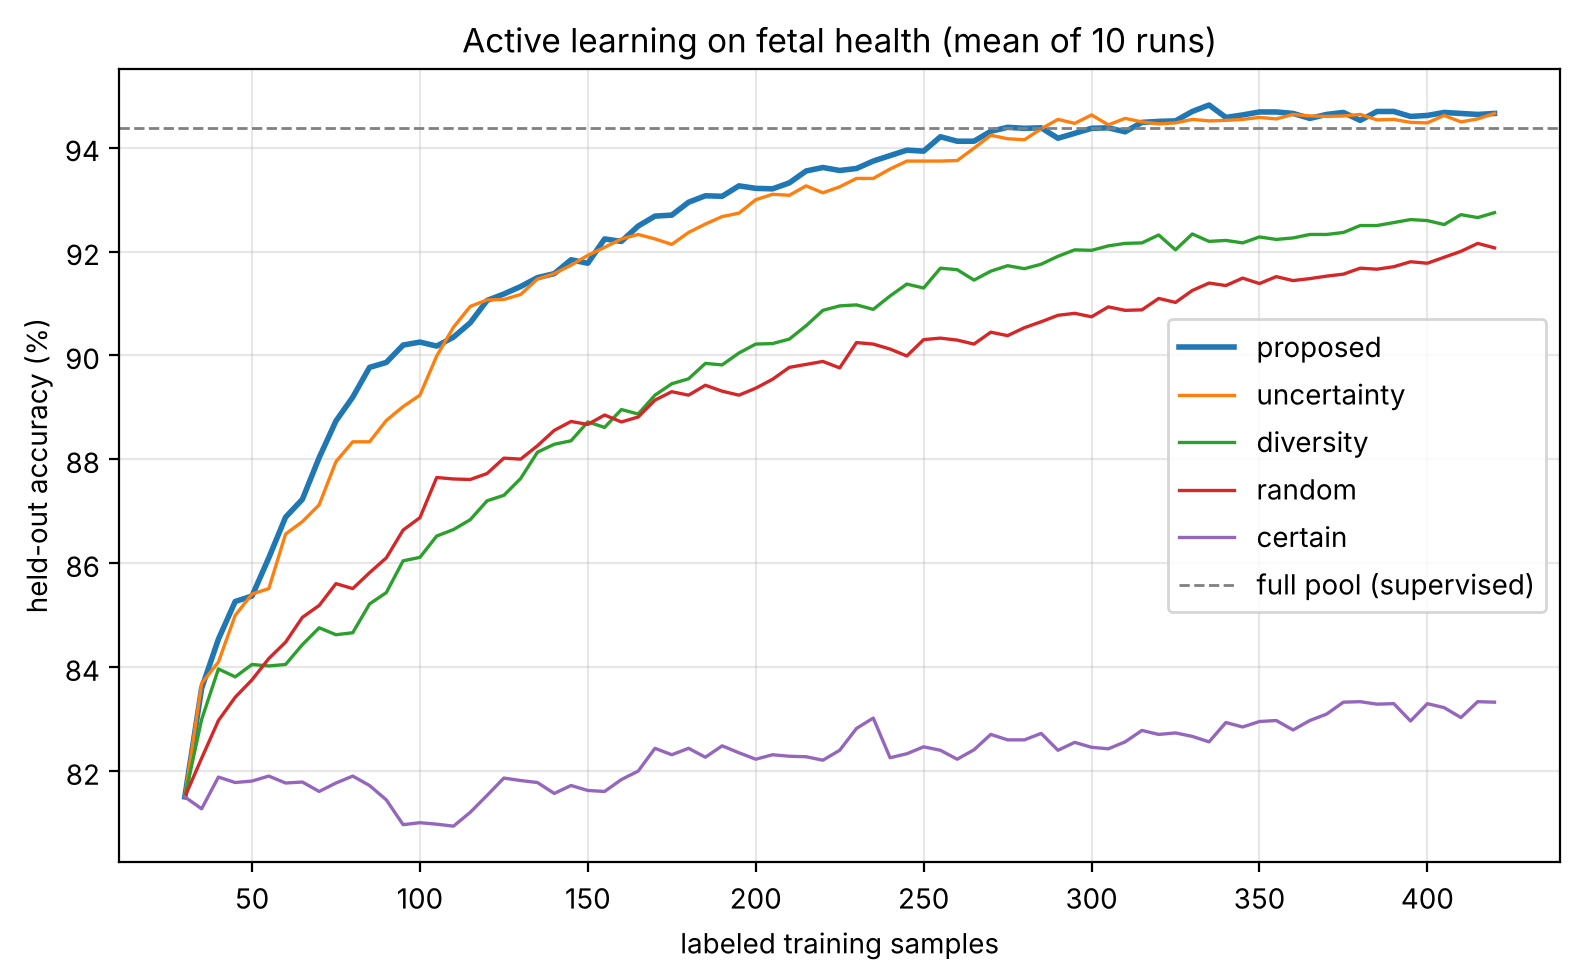

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for s in STRATEGIES:
    c = np.mean([r['curve'] for r in results[s]], axis=0)
    ax.plot(results[s][0]['sizes'], c, label=s, lw=2 if s == 'proposed' else 1.2)
ax.axhline(np.mean(full), color='grey', ls='--', lw=1, label='full pool (supervised)')
ax.set_xlabel('labeled training samples'); ax.set_ylabel('held-out accuracy (%)')
ax.set_title('Active learning on fetal health (mean of %d runs)' % N_RUNS)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Proposed method: per-class metrics and confusion matrix (pooled over runs)

              precision    recall  f1-score   support

      Normal     0.9601    0.9788    0.9694      8146
     Suspect     0.8667    0.7871    0.8249      1437
Pathological     0.9369    0.9097    0.9231       897

    accuracy                         0.9466     10480
   macro avg     0.9212    0.8918    0.9058     10480
weighted avg     0.9453    0.9466    0.9456     10480



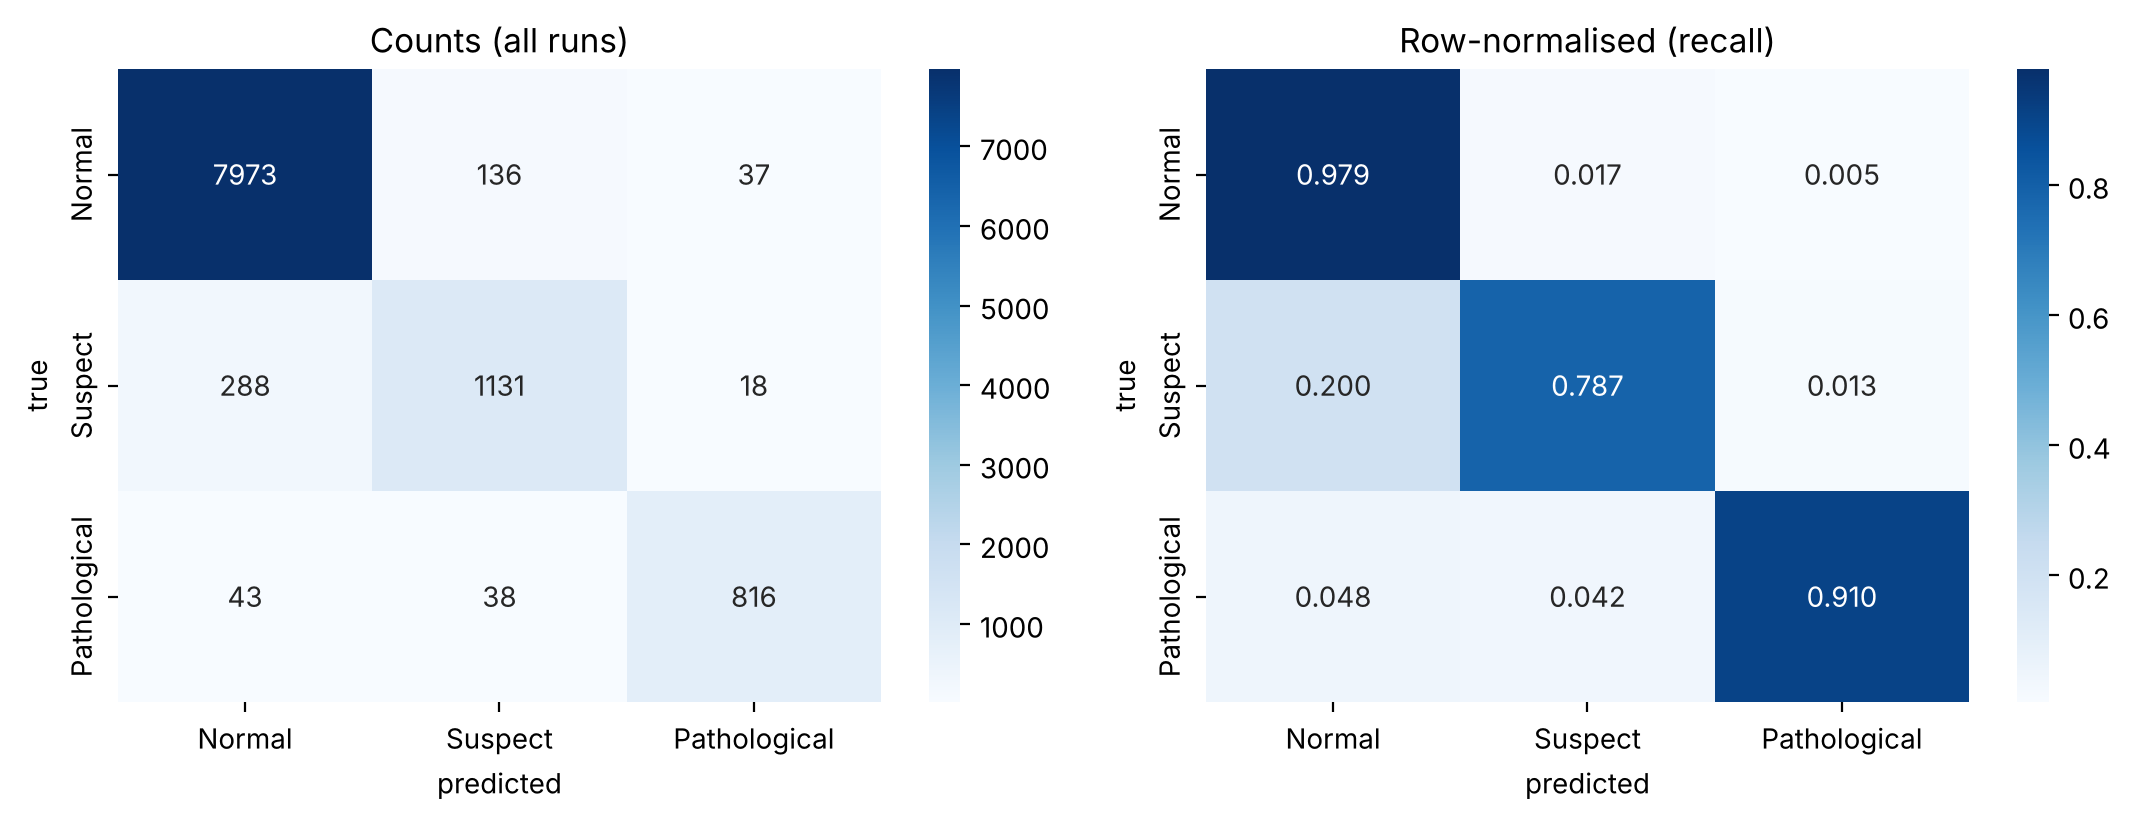

In [12]:
yt = np.concatenate([r['y_test'] for r in results['proposed']])
yp = np.concatenate([r['y_pred'] for r in results['proposed']])
print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(yt, yp)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title('Counts (all runs)'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.3f', cmap='Blues', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_title('Row-normalised (recall)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
plt.tight_layout(); plt.show()

## Class balance of the queried samples

In [13]:
bal = {}
for s in STRATEGIES:
    counts = np.mean([np.bincount(r['y_train'], minlength=3) for r in results[s]], axis=0)
    bal[s] = dict(zip(CLASS_NAMES, counts.round(1)))
bal['dataset (scaled to 420)'] = dict(zip(CLASS_NAMES, (np.bincount(y_all) / len(y_all) * 420).round(1)))
pd.DataFrame(bal).T

,Normal,Suspect,Pathological
proposed,228.4,122.2,69.4
uncertainty,231.6,121.0,67.4
diversity,252.9,87.0,80.1
random,329.6,58.8,31.6
certain,410.3,7.0,2.7
dataset (scaled to 420),327.0,58.3,34.8
